<a href="https://colab.research.google.com/github/SUCCESSneeded/practice/blob/main/Mlmaths.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import random

In [3]:
l=[]
for i in range(10000):
  a=random.randint(1,6)
  b=random.randint(1,6)
  l.append(a+b)

In [4]:
len(l)

10000

In [5]:
l[:5]

[4, 6, 9, 5, 8]

In [6]:
s=(pd.Series(l).value_counts()/pd.Series(l).value_counts().sum()).sort_index()
print(s)

2     0.0315
3     0.0552
4     0.0823
5     0.1145
6     0.1408
7     0.1623
8     0.1374
9     0.1143
10    0.0863
11    0.0507
12    0.0247
Name: count, dtype: float64


<Axes: >

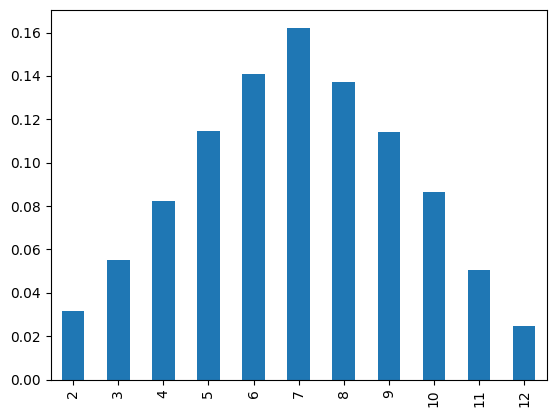

In [7]:
s.plot(kind='bar')

<Axes: >

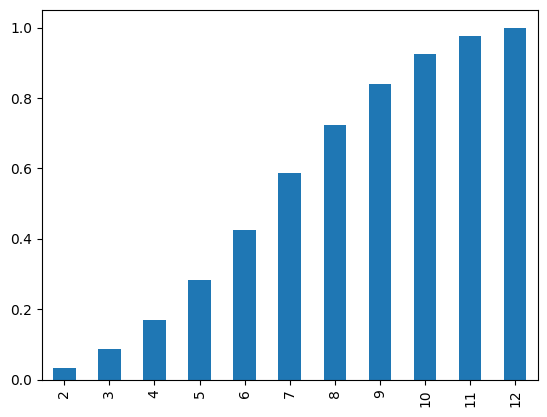

In [8]:
np.cumsum(s).plot(kind='bar')

PARAMETRIC DENSITY ESTIMATION

In [9]:
from numpy.random import normal

sample=normal(loc=50,scale=5,size=1000)
print(sample)
#loc=mean ,scale=std

[47.5674308  50.53611742 56.65742698 46.25387626 44.83202101 57.46585712
 57.66890686 46.48253122 48.14790528 51.7979701  51.03793929 53.92230917
 46.03969004 52.40053353 53.66239579 48.49314471 46.50671817 54.72815944
 47.98268487 50.11261189 53.10861628 51.81738608 47.71758467 68.01669829
 51.52482864 51.22764506 43.81691202 47.21397686 53.08643385 53.51809491
 45.75705099 45.88454795 65.63336333 39.91543946 43.44059474 46.67761939
 44.30076575 51.98528401 51.18118008 49.71784635 56.75619475 46.432193
 56.02202341 54.58095891 45.33970689 53.05336984 55.85014411 53.2781166
 58.46216516 39.61466176 52.21066458 41.87220105 46.89888118 51.07601932
 46.5679412  44.29568089 39.10539087 54.71496368 55.23455197 65.70038588
 52.04049837 58.47831623 51.6142311  36.85581329 56.45866267 46.40774126
 48.70323641 53.75758395 46.16853086 57.19089075 47.34443168 46.5633218
 55.53417695 58.29023554 55.00508945 50.10554688 53.02048303 44.6340911
 49.20896034 54.39259502 49.27765868 49.7832972  53.0649

In [10]:
sample.mean()

np.float64(49.932809532761034)

(array([  9.,  29.,  94., 206., 261., 226., 114.,  46.,  11.,   4.]),
 array([34.27839765, 37.65222772, 41.02605778, 44.39988784, 47.77371791,
        51.14754797, 54.52137803, 57.8952081 , 61.26903816, 64.64286822,
        68.01669829]),
 <BarContainer object of 10 artists>)

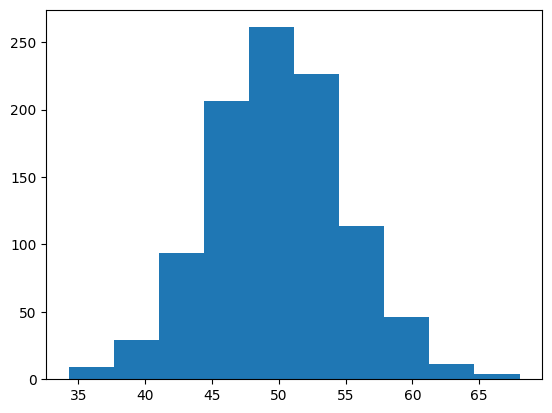

In [11]:
plt.hist(sample,bins=10)

In [12]:
sample_mean=sample.mean()
sample_std=sample.std()

In [13]:
from scipy.stats import norm
dist=norm(sample_mean,sample_std)

In [14]:
sample.min()

np.float64(34.27839765275805)

In [15]:
sample.max()

np.float64(68.016698286894)

In [16]:
# generating 100 datapts
values=np.linspace(sample.min(),sample.max(),100)

In [17]:
probabilities=[dist.pdf(value) for value in values]

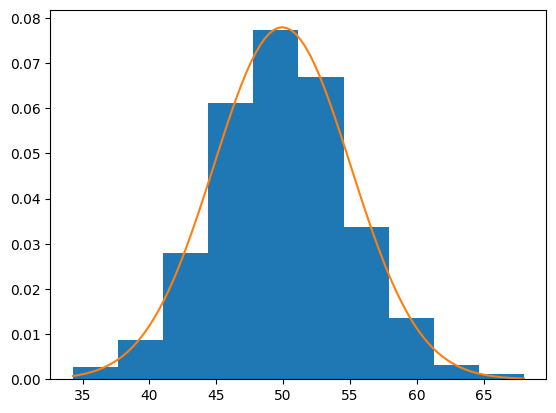

In [18]:
plt.hist(sample,bins=10,density=True)
plt.plot(values,probabilities)

/tmp/ipykernel_2053/1482356190.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(sample)


<Axes: ylabel='Density'>

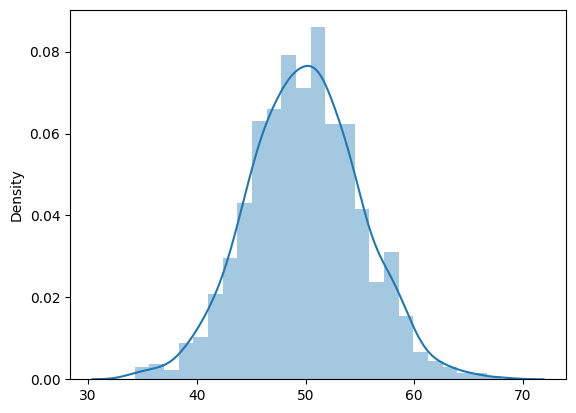

In [19]:
import seaborn as sns
sns.distplot(sample)

KDE

In [20]:
sample1=normal(loc=20,scale=5,size=300)
sample2=normal(loc=40,scale=5,size=700)
sample=np.hstack((sample1,sample2))

In [21]:
sample

array([21.87227122, 22.08968965, 15.08677649, 21.33626191, 24.17186359,
       23.36681828, 18.29822488, 23.00053575, 32.39355006, 33.17356827,
        8.76132581, 14.80783244, 12.15125254, 26.10169336, 23.35862586,
       26.146218  , 17.10321531, 20.23846092, 22.11456906, 29.10519774,
       22.40984172, 22.75019333, 19.20447669, 22.72750978, 21.99643571,
       17.95277654, 22.38159836, 19.38733785, 17.86007337, 16.77748846,
       18.03712572, 10.22389424, 23.14027679, 16.95269975, 18.222857  ,
       18.55053701,  8.00115417, 22.08352905, 18.22918848, 25.03002531,
       30.09966757, 18.52463648, 16.16323795, 25.7051673 , 24.44164011,
       24.99511769, 13.78799862, 19.72343009, 18.37419139, 20.17475469,
        8.44666877, 28.99938608, 21.45887441, 17.58364813, 19.8415999 ,
       17.28836461, 20.08864369, 19.66837845, 23.54248808, 19.08045431,
       21.45255255, 16.26633396, 11.96151853, 22.0194563 , 19.59370759,
       19.51033138, 18.23375062, 16.73667323, 12.99548041, 20.32

(array([ 4.,  1.,  4.,  1.,  7.,  7., 11., 11., 13., 12., 24., 27., 33.,
        26., 28., 18., 13., 18., 11., 15.,  7.,  9.,  7., 10., 15., 16.,
        25., 27., 49., 44., 40., 58., 50., 63., 42., 50., 45., 44., 29.,
        22., 20., 11.,  7.,  9.,  7.,  0.,  5.,  2.,  1.,  2.]),
 array([ 7.66541906,  8.63243805,  9.59945705, 10.56647604, 11.53349504,
        12.50051403, 13.46753303, 14.43455202, 15.40157102, 16.36859001,
        17.33560901, 18.302628  , 19.269647  , 20.23666599, 21.20368499,
        22.17070398, 23.13772298, 24.10474197, 25.07176097, 26.03877996,
        27.00579896, 27.97281795, 28.93983695, 29.90685594, 30.87387494,
        31.84089393, 32.80791293, 33.77493192, 34.74195092, 35.70896991,
        36.67598891, 37.6430079 , 38.6100269 , 39.57704589, 40.54406489,
        41.51108388, 42.47810288, 43.44512187, 44.41214087, 45.37915986,
        46.34617886, 47.31319785, 48.28021685, 49.24723584, 50.21425484,
        51.18127383, 52.14829283, 53.11531182, 54.08233082,

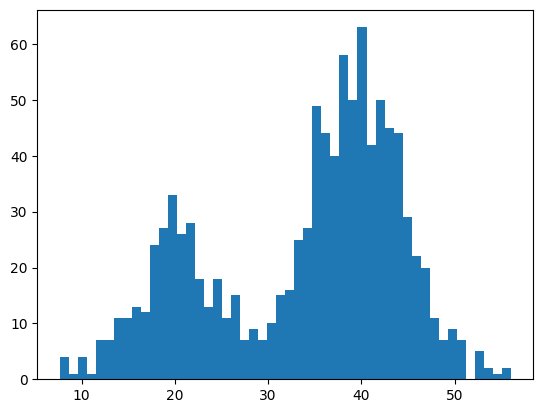

In [22]:
plt.hist(sample,bins=50)

In [23]:
from sklearn.neighbors import KernelDensity

model=KernelDensity(kernel='gaussian',bandwidth=2)

#CONVERT data into 2D array
sample=sample.reshape(len(sample),1)
model.fit(sample)

KernelDensity(bandwidth=2)

In [24]:
values=np.linspace(sample.min(),sample.max(),100)
values=values.reshape(len(values),1)


In [25]:
probabilities=model.score_samples(values)
probabilities=np.exp(probabilities)

score_sample(values) returns teh log density of the input samples() method of the kernel density returns the logarithm of te PDE rather than the actual PdE

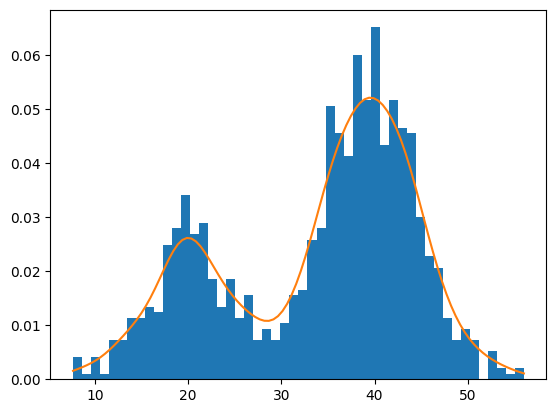

In [26]:
plt.hist(sample,bins=50,density=True)
plt.plot(values,probabilities)
plt.show()

<Axes: ylabel='Density'>

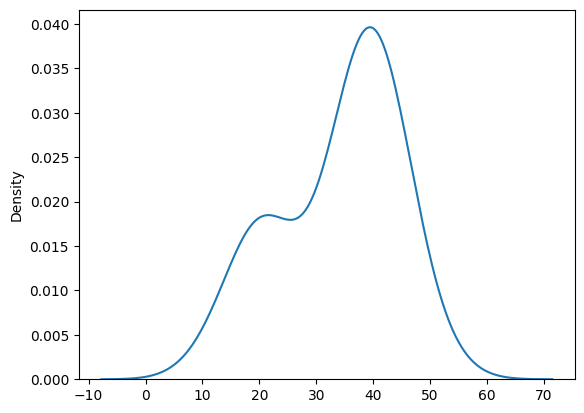

In [27]:
sns.kdeplot(data=sample.reshape(1000),bw_adjust=2)

CDF for PDF